
# EN3160 Assignment 2: Fitting and Alignment

**Name:** Gunasekara H.M
**Index Number:** 230208C  
**Course:** EN3160

## Introduction

This assignment explores computer vision techniques for blob detection, robust geometric model fitting, homography-based image warping, and PCB image alignment. The methods are implemented using Python and OpenCV, and their performance is evaluated using visual results and numerical measurements.


In [14]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Additional libraries used in this assignment
from scipy.optimize import minimize
from scipy import linalg

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)


OpenCV version: 5.0.0
NumPy version: 2.4.6



## Question 1: Sunflower Blob Detection

### Method

The sunflower image is processed at multiple scales using Gaussian smoothing and the Laplacian operator. Blob candidates are identified by finding local extrema in scale space. The detected blobs are represented as circles, with their locations and radii determined from the detected scale.

The `cv2.HoughCircles` function is not used.


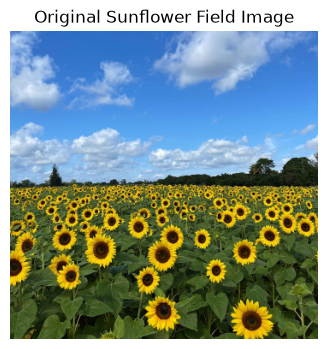

In [15]:

image_path = "images/the_berry_farms_sunflower_field.jpeg"

img = cv2.imread(image_path, cv2.IMREAD_REDUCED_COLOR_4)

if img is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(7, 4))
plt.imshow(img_rgb)
plt.title("Original Sunflower Field Image")
plt.axis("off")
plt.show()


In [16]:

# Question 1: LoG detection of prominent sunflower centers

from scipy.ndimage import maximum_filter

# Normalize the grayscale image
gray_float = gray.astype(np.float32) / 255.0

# Use a smaller scale range to focus on sunflower centers
sigma_values = np.arange(1.5, 6.5, 0.5)

# Store signed, scale-normalized LoG responses
# Dark blobs generally produce positive Laplacian responses
log_volume = []

for sigma in sigma_values:
    blurred = cv2.GaussianBlur(
        gray_float,
        (0, 0),
        sigmaX=float(sigma),
        sigmaY=float(sigma)
    )

    laplacian = cv2.Laplacian(
        blurred,
        cv2.CV_32F,
        ksize=3
    )

    # Scale normalization
    response = (sigma ** 2) * laplacian
    log_volume.append(response)

log_volume = np.stack(log_volume, axis=0)

print("Scale-space shape:", log_volume.shape)
print(f"Sigma range: {sigma_values[0]:.1f} "
      f"to {sigma_values[-1]:.1f}")

# Find local maxima across x, y, and scale.
# Positive responses favor dark centers surrounded by brighter regions.
local_maxima = (
    log_volume ==
    maximum_filter(log_volume, size=(3, 3, 3))
)

# Ignore weak responses using a relative threshold
positive_peak = max(float(log_volume.max()), 0.0)
response_threshold = 0.12 * positive_peak

candidate_indices = np.argwhere(
    local_maxima & (log_volume >= response_threshold)
)

# Sort candidates from strongest to weakest
candidate_indices = sorted(
    candidate_indices,
    key=lambda p: log_volume[tuple(p)],
    reverse=True
)

# Non-maximum suppression:
# keep strong detections separated from one another
detected_blobs = []
minimum_separation = 10  # pixels
maximum_blobs = 45        # limit to prominent detections

for scale_idx, row, col in candidate_indices:
    sigma = float(sigma_values[scale_idx])
    response = float(log_volume[scale_idx, row, col])

    # Approximate radius for a 2D LoG blob
    radius = float(np.sqrt(2) * sigma)

    too_close = False

    for blob in detected_blobs:
        distance = np.hypot(
            col - blob["x"],
            row - blob["y"]
        )

        # Suppress nearby detections, especially duplicates
        separation = max(
            minimum_separation,
            0.8 * min(radius, blob["radius"])
        )

        if distance < separation:
            too_close = True
            break

    if not too_close:
        detected_blobs.append({
            "x": int(col),
            "y": int(row),
            "sigma": sigma,
            "radius": radius,
            "response": response
        })

    if len(detected_blobs) >= maximum_blobs:
        break

print("Prominent blob candidates:", len(detected_blobs))


Scale-space shape: (10, 360, 360)
Sigma range: 1.5 to 6.0
Prominent blob candidates: 45


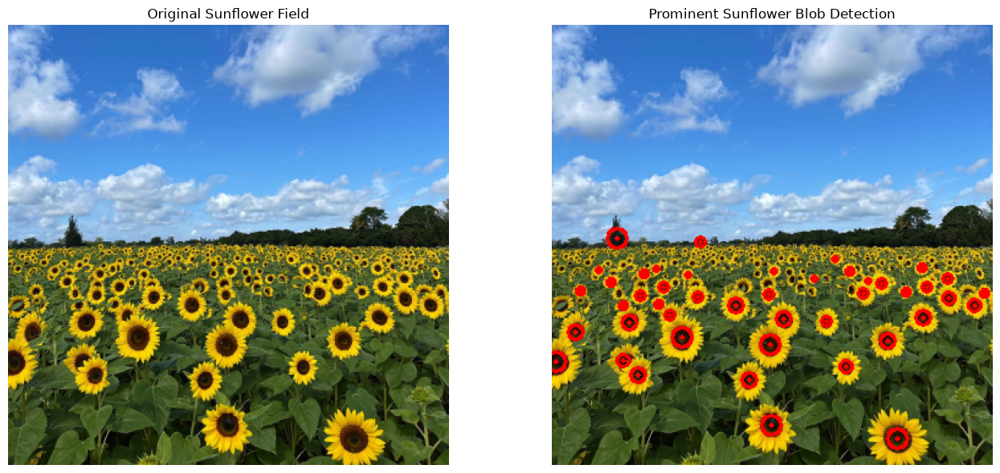


Largest retained blob detections
-----------------------------------------------------------------
Rank  Center (x, y)       Radius (px)   Sigma     Response    
1     (306, 214)     3.54          2.50      1.5382      
2     (269, 211)     4.24          3.00      1.5184      
3     (119, 222)     4.24          3.00      1.5149      
4     (303, 239)     5.66          4.00      1.5115      
5     (240, 279)     4.95          3.50      1.4977      
6     (224, 242)     4.24          3.00      1.4937      
7     (323, 207)     3.54          2.50      1.4884      
8     (345, 229)     4.95          3.50      1.4853      
9     (324, 223)     4.95          3.50      1.4557      
10    (150, 229)     5.66          4.00      1.4551      

Scales tested: 1.5 to 6.0
Scale increment: 0.5
Total retained detections: 45


In [17]:

# Display the prominent LoG detections

result_image = img_rgb.copy()

for blob in detected_blobs:
    center = (blob["x"], blob["y"])
    radius = max(1, int(round(blob["radius"])))

    # Draw a green circle around each detected blob
    cv2.circle(
        result_image,
        center,
        radius,
        (255, 0, 0),
        2
    )

    # Mark the center in red
    cv2.circle(
        result_image,
        center,
        2,
        (255, 0, 0),
        -1
    )

# Display original and detected images
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(img_rgb)
axes[0].set_title("Original Sunflower Field")
axes[0].axis("off")

axes[1].imshow(result_image)
axes[1].set_title("Prominent Sunflower Blob Detection")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Report the ten strongest retained detections
print("\nLargest retained blob detections")
print("-" * 65)
print(f"{'Rank':<6}{'Center (x, y)':<20}"
      f"{'Radius (px)':<14}{'Sigma':<10}{'Response':<12}")

for rank, blob in enumerate(detected_blobs[:10], start=1):
    print(
        f"{rank:<6}"
        f"({blob['x']}, {blob['y']})".ljust(20),
        f"{blob['radius']:<14.2f}"
        f"{blob['sigma']:<10.2f}"
        f"{blob['response']:<12.4f}"
    )

print(f"\nScales tested: {sigma_values[0]:.1f} "
      f"to {sigma_values[-1]:.1f}")
print(f"Scale increment: {sigma_values[1] - sigma_values[0]:.1f}")
print(f"Total retained detections: {len(detected_blobs)}")



### Results and Discussion

The sunflower field image was analyzed using a scale-normalized Laplacian of Gaussian (LoG) detector. The standard deviation, $\sigma$, was varied from 1.5 to 6.0 pixels in increments of 0.5 pixels. Local maxima in the scale-space volume were identified to detect prominent blob-like structures.

To reduce unwanted detections, a response threshold and non-maximum suppression were applied. The detected scale was converted into an approximate blob radius using

$$
r \approx \sqrt{2}\sigma
$$

The algorithm retained **45 blob candidates** and displayed them as circles over the original image. The visualization shows that many of the detected circles correspond to prominent sunflower centers, particularly in the foreground and middle ground. Some detections occur on other structures, including vegetation and background objects, because LoG detects blob-like intensity patterns rather than specifically recognizing flowers.

The results demonstrate that scale-space analysis can identify prominent circular structures in an image. However, detection performance depends on the selected scale range, response threshold, and minimum separation between detections.



## Question 2: RANSAC Line and Circle Fitting

### Objective

The objective is to estimate a line and a circle from a noisy point set containing points belonging to both models.

RANSAC (Random Sample Consensus) is used to identify the inliers of each model while rejecting points that do not fit it. The line is estimated first, and its inliers are removed before fitting the circle to the remaining points.

The line is represented by

$$
ax+by=d,\qquad a^2+b^2=1
$$

where $(a,b)$ is the unit normal vector and $d$ is the perpendicular distance from the origin.

The circle is represented by its center $(x_c,y_c)$ and radius $r$.


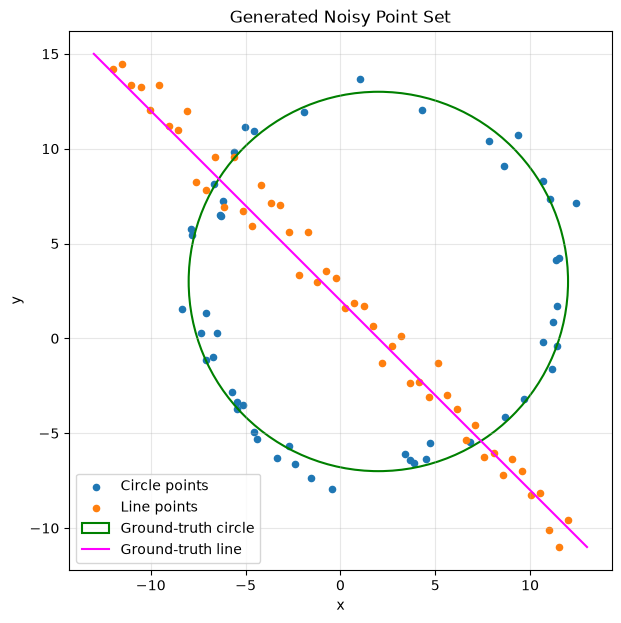

Total points: 100
Circle points: 50
Line points: 50


In [18]:

# Question 2: Generate a noisy point set containing a line and a circle

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Uncomment this line for reproducible results
np.random.seed(0)

# Parameters from Listing 1
N = 100
half_n = N // 2

# Generate noisy circle points
r = 10
x0_gt, y0_gt = 2, 3
s = r / 16

t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)

x = x0_gt + (r + n) * np.cos(t)
y = y0_gt + (r + n) * np.sin(t)

X_circ = np.hstack((
    x.reshape(half_n, 1),
    y.reshape(half_n, 1)
))

# Generate noisy line points
s = 1.0
m, b = -1, 2

x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)

X_line = np.hstack((
    x.reshape(half_n, 1),
    y.reshape(half_n, 1)
))

# Combine the circle and line points
X = np.vstack((X_circ, X_line))

# Display the generated point set and ground-truth models
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(X_circ[:, 0], X_circ[:, 1],
           s=20, label="Circle points")
ax.scatter(X_line[:, 0], X_line[:, 1],
           s=20, label="Line points")

ground_truth_circle = plt.Circle(
    (x0_gt, y0_gt), r,
    fill=False, color="green", linewidth=1.5,
    label="Ground-truth circle"
)
ax.add_patch(ground_truth_circle)

x_plot = np.array([-13, 13])
ax.plot(x_plot, m * x_plot + b,
        color="magenta", label="Ground-truth line")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Generated Noisy Point Set")
ax.axis("equal")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

print("Total points:", len(X))
print("Circle points:", len(X_circ))
print("Line points:", len(X_line))


In [19]:

# Question 2(a): Estimate the line using RANSAC

def line_from_two_points(p1, p2):
    """Return normalized line parameters (a, b, d) for ax + by = d."""
    direction = p2 - p1

    if np.linalg.norm(direction) < 1e-10:
        return None

    # A normal vector perpendicular to the line direction
    normal = np.array([-direction[1], direction[0]], dtype=float)
    normal /= np.linalg.norm(normal)

    a, b = normal
    d = np.dot(normal, p1)

    return np.array([a, b, d])


def line_distances(points, model):
    """Perpendicular distances from points to ax + by = d."""
    a, b, d = model
    return np.abs(points[:, 0] * a + points[:, 1] * b - d)


def fit_line_tls(points):
    """Refine a line using total least squares."""
    centroid = points.mean(axis=0)
    _, _, vh = np.linalg.svd(points - centroid, full_matrices=False)

    normal = vh[-1]
    normal /= np.linalg.norm(normal)
    d = np.dot(normal, centroid)

    return np.array([normal[0], normal[1], d])


# RANSAC parameters
LINE_THRESHOLD = 1.5
LINE_ITERATIONS = 3000
MIN_LINE_INLIERS = 30

rng = np.random.default_rng(42)

best_line_sample = None
best_line_model = None
best_line_inliers = None

for _ in range(LINE_ITERATIONS):

    # Select two different points randomly
    sample_indices = rng.choice(len(X), size=2, replace=False)
    p1, p2 = X[sample_indices]

    candidate = line_from_two_points(p1, p2)

    if candidate is None:
        continue

    distances = line_distances(X, candidate)
    inliers = distances < LINE_THRESHOLD

    if (best_line_inliers is None or
            np.count_nonzero(inliers) >
            np.count_nonzero(best_line_inliers)):

        best_line_model = candidate
        best_line_inliers = inliers
        best_line_sample = X[sample_indices].copy()


if np.count_nonzero(best_line_inliers) < MIN_LINE_INLIERS:
    raise RuntimeError(
        "Not enough line inliers. Adjust LINE_THRESHOLD or iterations."
    )

# Refine the best line using its consensus points
line_inliers = best_line_inliers
line_model = fit_line_tls(X[line_inliers])

a, b, d = line_model

print("Estimated line: ax + by = d")
print(f"a = {a:.4f}")
print(f"b = {b:.4f}")
print(f"d = {d:.4f}")
print(f"a^2 + b^2 = {a**2 + b**2:.6f}")
print("Line inliers:", np.count_nonzero(line_inliers))
print("Line outliers:", np.count_nonzero(~line_inliers))


Estimated line: ax + by = d
a = 0.7156
b = 0.6985
d = 1.5618
a^2 + b^2 = 1.000000
Line inliers: 57
Line outliers: 43


In [20]:

# Question 2(b): Remove line inliers and estimate the circle

# Keep points not classified as line inliers
remaining_points = X[~line_inliers]

print("Points remaining after line removal:", len(remaining_points))


def circle_from_three_points(p1, p2, p3):
    """Calculate circle center and radius from three points."""
    matrix = 2 * np.array([
        p2 - p1,
        p3 - p1
    ], dtype=float)

    rhs = np.array([
        np.dot(p2, p2) - np.dot(p1, p1),
        np.dot(p3, p3) - np.dot(p1, p1)
    ])

    if abs(np.linalg.det(matrix)) < 1e-8:
        return None

    center = np.linalg.solve(matrix, rhs)
    radius = np.linalg.norm(center - p1)

    return np.array([center[0], center[1], radius])


def circle_radial_errors(points, circle):
    """Absolute radial errors for a circle (xc, yc, r)."""
    xc, yc, radius = circle
    distances = np.sqrt(
        (points[:, 0] - xc)**2 +
        (points[:, 1] - yc)**2
    )
    return np.abs(distances - radius)


# RANSAC parameters for the circle
CIRCLE_THRESHOLD = 1.3
CIRCLE_ITERATIONS = 4000
MIN_CIRCLE_INLIERS = 30

best_circle_model = None
best_circle_sample = None
best_circle_inliers = None

for _ in range(CIRCLE_ITERATIONS):

    # Three points are needed to define a circle
    sample_indices = rng.choice(
        len(remaining_points), size=3, replace=False
    )
    sample = remaining_points[sample_indices]

    candidate = circle_from_three_points(
        sample[0], sample[1], sample[2]
    )

    if candidate is None:
        continue

    # Reject unrealistic circles
    if not np.isfinite(candidate).all() or candidate[2] <= 0:
        continue

    errors = circle_radial_errors(remaining_points, candidate)
    inliers = errors < CIRCLE_THRESHOLD

    if (best_circle_inliers is None or
            np.count_nonzero(inliers) >
            np.count_nonzero(best_circle_inliers)):

        best_circle_model = candidate
        best_circle_inliers = inliers
        best_circle_sample = sample.copy()


if (best_circle_inliers is None or
        np.count_nonzero(best_circle_inliers) < MIN_CIRCLE_INLIERS):
    raise RuntimeError(
        "Not enough circle inliers. Adjust CIRCLE_THRESHOLD or iterations."
    )

circle_inliers = best_circle_inliers
circle_points = remaining_points[circle_inliers]


# Refine the circle by minimizing squared radial errors
def circle_objective(params, points):
    errors = circle_radial_errors(points, params)
    return np.sum(errors**2)


optimization = minimize(
    circle_objective,
    x0=best_circle_model,
    args=(circle_points,),
    method="Nelder-Mead",
    options={"maxiter": 5000, "xatol": 1e-8}
)

best_circle = optimization.x

xc, yc, radius = best_circle

print("\nEstimated circle")
print(f"Center x = {xc:.4f}")
print(f"Center y = {yc:.4f}")
print(f"Radius   = {radius:.4f}")
print("Circle inliers:", np.count_nonzero(circle_inliers))
print("Circle consensus points:",
      len(circle_points))
print("Optimization successful:", optimization.success)


Points remaining after line removal: 43

Estimated circle
Center x = 1.8696
Center y = 3.0655
Radius   = 9.9493
Circle inliers: 43
Circle consensus points: 43
Optimization successful: True


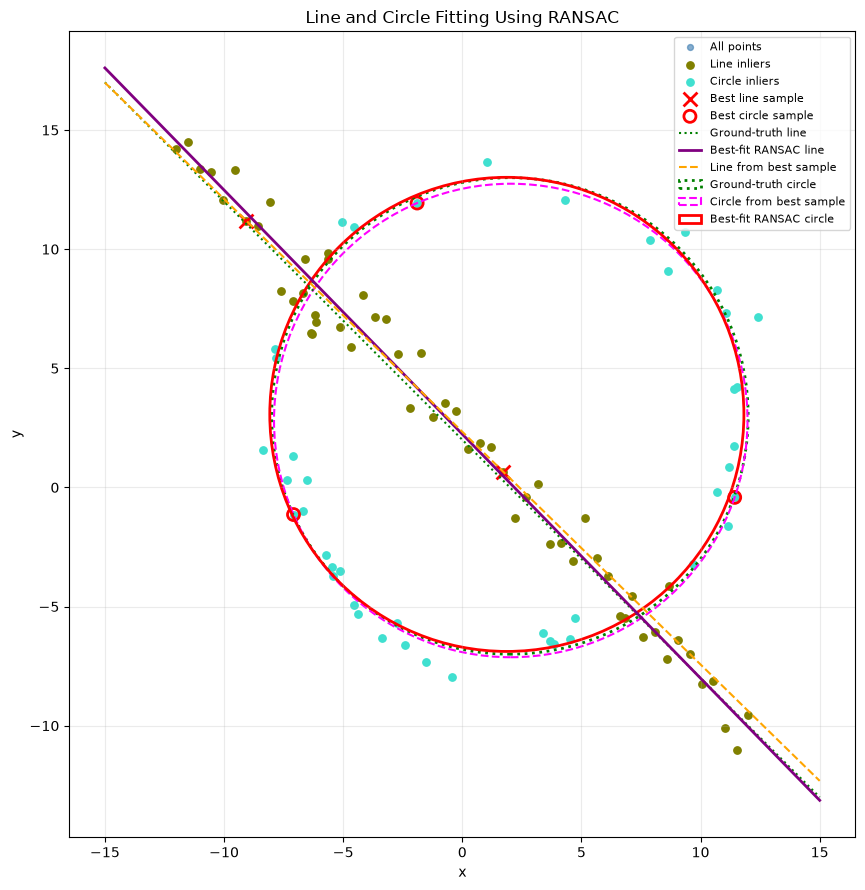

In [21]:

# Question 2(c): Plot the complete RANSAC results

fig, ax = plt.subplots(figsize=(9, 9))

# All points
ax.scatter(
    X[:, 0], X[:, 1],
    s=18, color="steelblue", alpha=0.65,
    label="All points"
)

# Line inliers
ax.scatter(
    X[line_inliers, 0], X[line_inliers, 1],
    s=28, color="olive",
    label="Line inliers"
)

# Circle inliers
ax.scatter(
    circle_points[:, 0], circle_points[:, 1],
    s=28, color="turquoise",
    label="Circle inliers"
)

# Best two-point sample for the line
ax.scatter(
    best_line_sample[:, 0], best_line_sample[:, 1],
    marker="x", s=100, linewidths=2,
    color="red", label="Best line sample"
)

# Best three-point sample for the circle
ax.scatter(
    best_circle_sample[:, 0], best_circle_sample[:, 1],
    marker="o", s=75, facecolors="none",
    edgecolors="red", linewidths=2,
    label="Best circle sample"
)

# Ground-truth line: y = -x + 2
x_plot = np.linspace(-15, 15, 400)

ax.plot(
    x_plot, -x_plot + 2,
    color="green", linestyle=":",
    linewidth=1.5, label="Ground-truth line"
)

# Refined RANSAC line: ax + by = d
a, b_line, d = line_model

if abs(b_line) > 1e-8:
    y_fit = (d - a * x_plot) / b_line
    ax.plot(
        x_plot, y_fit,
        color="purple", linewidth=2,
        label="Best-fit RANSAC line"
    )
else:
    x_vertical = d / a
    ax.axvline(
        x_vertical, color="purple", linewidth=2,
        label="Best-fit RANSAC line"
    )

# Line estimated from the best two-point sample
sample_line = line_from_two_points(
    best_line_sample[0], best_line_sample[1]
)
as_, bs_, ds_ = sample_line

if abs(bs_) > 1e-8:
    ax.plot(
        x_plot, (ds_ - as_ * x_plot) / bs_,
        color="orange", linestyle="--",
        linewidth=1.5, label="Line from best sample"
    )

# Ground-truth circle
ground_truth_circle = plt.Circle(
    (x0_gt, y0_gt), r,
    fill=False, color="green", linestyle=":",
    linewidth=2, label="Ground-truth circle"
)
ax.add_patch(ground_truth_circle)

# Circle estimated from the best RANSAC sample
sample_circle = plt.Circle(
    (best_circle_model[0], best_circle_model[1]),
    best_circle_model[2],
    fill=False, color="magenta", linestyle="--",
    linewidth=1.5, label="Circle from best sample"
)
ax.add_patch(sample_circle)

# Refined best-fit circle
fitted_circle = plt.Circle(
    (xc, yc), radius,
    fill=False, color="red",
    linewidth=2, label="Best-fit RANSAC circle"
)
ax.add_patch(fitted_circle)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Line and Circle Fitting Using RANSAC")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.25)
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

ax.plot(
    x_plot, -x_plot + 2,
    color="green", linestyle=":",
    linewidth=1.5, label="Ground-truth line"
)


### Results and Discussion

RANSAC was used to estimate a line and a circle from the noisy point set. The line was estimated first by randomly selecting two points and calculating the perpendicular distances from all points to the candidate line. Points within the selected distance threshold were classified as line inliers. The best line was refined using total least squares while maintaining the unit-normal constraint.

After removing the line inliers, a circle was estimated from the remaining points. Each candidate circle was generated using three non-collinear points. Points whose radial errors were below the selected threshold were classified as circle inliers. The final circle parameters were refined by minimizing the sum of squared radial errors.

The fitted line and circle were compared with the ground-truth models used to generate the data. The estimated parameters and the visual plot can be used to assess how closely the fitted models follow the underlying point distributions. The number of inliers depends on the selected thresholds and the noise in the data.

### What Happens if the Circle Is Fitted First?

If the circle is fitted first, RANSAC attempts to identify the circular points while treating the remaining points as outliers. Most points belonging to the line do not lie near the circumference, so they can be rejected by an appropriate radial-error threshold. However, some line points may accidentally fall close to the circle and become false inliers.

After removing the circle inliers, RANSAC can be applied to the remaining points to estimate the line. Therefore, fitting the circle first can also work, provided that the thresholds and consensus criteria are selected carefully. The order of fitting can affect the results because points assigned to the first model are removed before estimating the second model.



## Question 3: Homography-Based Image Warping

### Objective

The objective of this experiment is to project an image onto a planar surface using a homography transformation.

An Avengers poster is projected onto the billboard in the background image. Four corresponding corner points are identified on the poster and the billboard surface. The homography matrix is calculated using these corresponding points and is used to warp the poster to match the perspective of the billboard.

Finally, the warped poster is blended with the background image to produce the composite image.


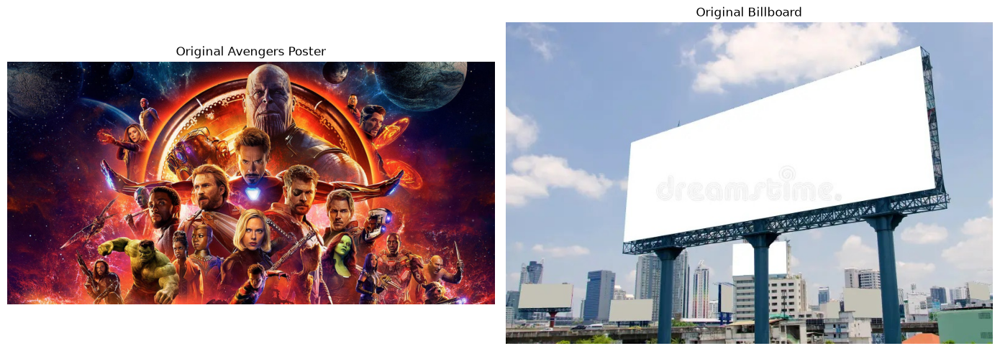

Poster dimensions: 1600 x 800
Billboard dimensions: 800 x 529


In [26]:

# Question 3: Load the Avengers poster and billboard image

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Input image paths
poster_path = "Images/avengers.jpg"
board_path = "Images/board.jpeg"

# Load images using OpenCV
poster = cv2.imread(poster_path)
board = cv2.imread(board_path)

# Check that both images were loaded
if poster is None:
    raise FileNotFoundError(
        f"Could not load Avengers poster: {poster_path}"
    )

if board is None:
    raise FileNotFoundError(
        f"Could not load billboard image: {board_path}"
    )

# Convert BGR to RGB for displaying with Matplotlib
poster_rgb = cv2.cvtColor(poster, cv2.COLOR_BGR2RGB)
board_rgb = cv2.cvtColor(board, cv2.COLOR_BGR2RGB)

# Display the original images
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(poster_rgb)
axes[0].set_title("Original Avengers Poster")
axes[0].axis("off")

axes[1].imshow(board_rgb)
axes[1].set_title("Original Billboard")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Poster dimensions:", poster.shape[1], "x", poster.shape[0])
print("Billboard dimensions:", board.shape[1], "x", board.shape[0])


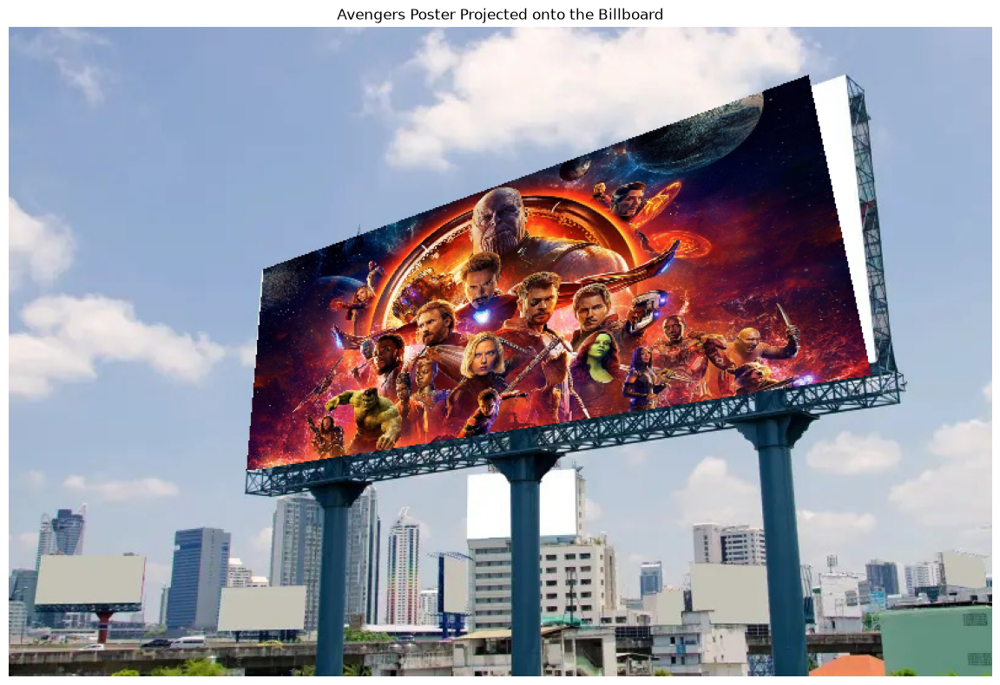

Homography matrix:
[[ 1.31802311e-01 -3.97643932e-02  2.07000000e+02]
 [-1.07526508e-01  1.63652741e-01  1.97000000e+02]
 [-2.23455144e-04 -1.15246066e-04  1.00000000e+00]]


In [32]:

# Question 3: Homography and perspective warping onto the billboard

# Get image dimensions
poster_h, poster_w = poster.shape[:2]
board_h, board_w = board.shape[:2]

# Four corners of the Avengers poster:
# top-left, top-right, bottom-right, bottom-left
source_points = np.float32([
    [0, 0],
    [poster_w - 1, 0],
    [poster_w - 1, poster_h - 1],
    [0, poster_h - 1]
])

# Approximate corners of the WHITE billboard surface
# for the provided 800 x 529 image.
# Order must match source_points.
destination_points = np.float32([
    [207, 197],  # Top-left
    [650, 39],   # Top-right
    [701, 283],  # Bottom-right
    [193, 361]   # Bottom-left
])

# Calculate the homography matrix
H = cv2.getPerspectiveTransform(
    source_points,
    destination_points
)

# Warp the poster into the billboard's perspective
warped_poster = cv2.warpPerspective(
    poster,
    H,
    (board_w, board_h)
)

# Create a mask covering the original poster
poster_mask = np.full(
    (poster_h, poster_w),
    255,
    dtype=np.uint8
)

# Transform the mask using the same homography
warped_mask = cv2.warpPerspective(
    poster_mask,
    H,
    (board_w, board_h),
    flags=cv2.INTER_NEAREST
)

# Blend the poster with the billboard background
# Only pixels inside the projected poster region are changed.
composite = board.copy()
region = warped_mask > 0

alpha = 1.0  # 1.0 = fully visible poster

composite[region] = (
    alpha * warped_poster[region].astype(np.float32)
    + (1 - alpha) * board[region].astype(np.float32)
).clip(0, 255).astype(np.uint8)

# Convert result to RGB for display
composite_rgb = cv2.cvtColor(
    composite,
    cv2.COLOR_BGR2RGB
)

# Display the projected result
plt.figure(figsize=(12, 8))
plt.imshow(composite_rgb)
plt.title("Avengers Poster Projected onto the Billboard")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Homography matrix:")
print(H)


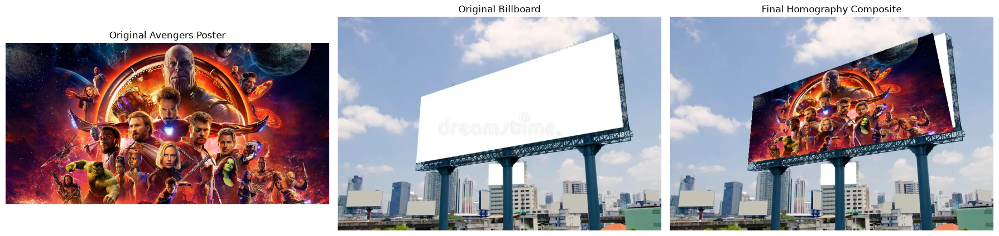

In [33]:

# Question 3: Display the original images and final composite

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(poster_rgb)
axes[0].set_title("Original Avengers Poster")
axes[0].axis("off")

axes[1].imshow(board_rgb)
axes[1].set_title("Original Billboard")
axes[1].axis("off")

axes[2].imshow(composite_rgb)
axes[2].set_title("Final Homography Composite")
axes[2].axis("off")

plt.tight_layout()
plt.show()



### Results and Discussion

The Avengers poster was projected onto the white billboard surface using a homography transformation. Four corresponding corner points were specified on the poster and the billboard. The homography matrix was calculated using `cv2.getPerspectiveTransform`, and `cv2.warpPerspective` was used to transform the poster into the perspective of the billboard.

A transformed mask was used to restrict the blending operation to the projected poster region. Consequently, the surrounding sky, supporting structure, and buildings remained unchanged.

The final composite demonstrates how homography can be used to project a planar image onto a surface with perspective distortion. The accuracy of the projection depends on the selection of the four destination points. Small inaccuracies in these coordinates can cause the poster to extend beyond the billboard boundaries or leave parts of the surface uncovered.

### Conclusion

This experiment demonstrates the application of homography-based image warping for perspective-correct image composition. The same technique can be used for virtual billboard advertisements, augmented reality, and architectural visualization.



# Question 4: PCB Image Alignment and Difference Images

## Method

The objective is to align PCB images with a reference PCB image and identify regions that differ between them.

### 1. SIFT Feature Detection

Scale-Invariant Feature Transform (SIFT) is used to detect distinctive keypoints and extract descriptors from the reference PCB image and each input PCB image.

### 2. Feature Matching

A brute-force matcher is used to compare the SIFT descriptors. Lowe's ratio test is applied to retain reliable feature matches and reduce incorrect correspondences.

### 3. Homography Estimation

The homography matrix is estimated from the matched feature points using RANSAC. This method rejects inconsistent matches and estimates the perspective transformation between the two PCB images.

### 4. Image Alignment and Difference Calculation

The input PCB image is warped into the coordinate system of the reference image using the estimated homography. An absolute pixel difference image is then calculated to highlight regions that differ between the aligned images.

### 5. Interpretation

Regions with large differences may indicate component variations, slight misalignment, illumination changes, shadows, or differences between the photographed boards. A large pixel difference alone does not prove that a component is faulty.


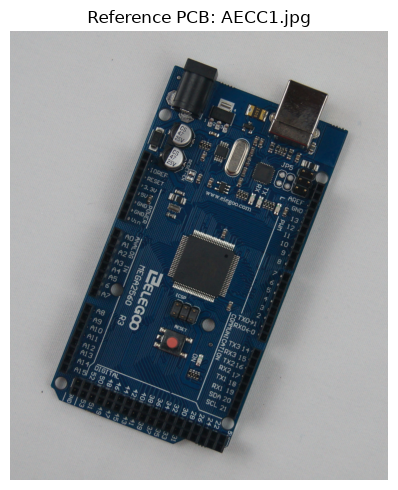

Reference: Images\pcb\AECC1.jpg
Reference dimensions: 2302 x 2730

Comparison images:
- AAAA1.jpg
- ADAD1.jpg
- AECC2.jpg
- AECC3.jpg
- AECC4.jpg

Total comparison images: 5


In [34]:

# Question 4: Load the reference PCB and all comparison images

from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Folder containing the six PCB images
image_folder = Path("Images") / "pcb"

if not image_folder.is_dir():
    raise FileNotFoundError(
        f"PCB folder not found: {image_folder.resolve()}\n"
        "Check that the notebook is in the assignment 2 folder."
    )

# Load the reference PCB
template_path = image_folder / "AECC1.jpg"
template = cv2.imread(str(template_path))

if template is None:
    raise FileNotFoundError(
        f"Could not load reference image: {template_path}"
    )

template_gray = cv2.cvtColor(
    template, cv2.COLOR_BGR2GRAY
)

# Find all supported image files
supported_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}

all_image_paths = sorted(
    path for path in image_folder.iterdir()
    if path.is_file()
    and path.suffix.lower() in supported_extensions
)

# Exclude the reference image
pcb_image_paths = [
    path for path in all_image_paths
    if path.resolve() != template_path.resolve()
]

if not pcb_image_paths:
    raise FileNotFoundError(
        "No comparison PCB images found in Images/pcb."
    )

# Display the reference image
plt.figure(figsize=(7, 5))
plt.imshow(cv2.cvtColor(template, cv2.COLOR_BGR2RGB))
plt.title("Reference PCB: AECC1.jpg")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Reference:", template_path)
print("Reference dimensions:", template.shape[1], "x", template.shape[0])
print("\nComparison images:")

for path in pcb_image_paths:
    print("-", path.name)

print("\nTotal comparison images:", len(pcb_image_paths))



Processing: AAAA1.jpg
Good matches: 90
RANSAC inliers: 7
Inlier ratio: 7.78%


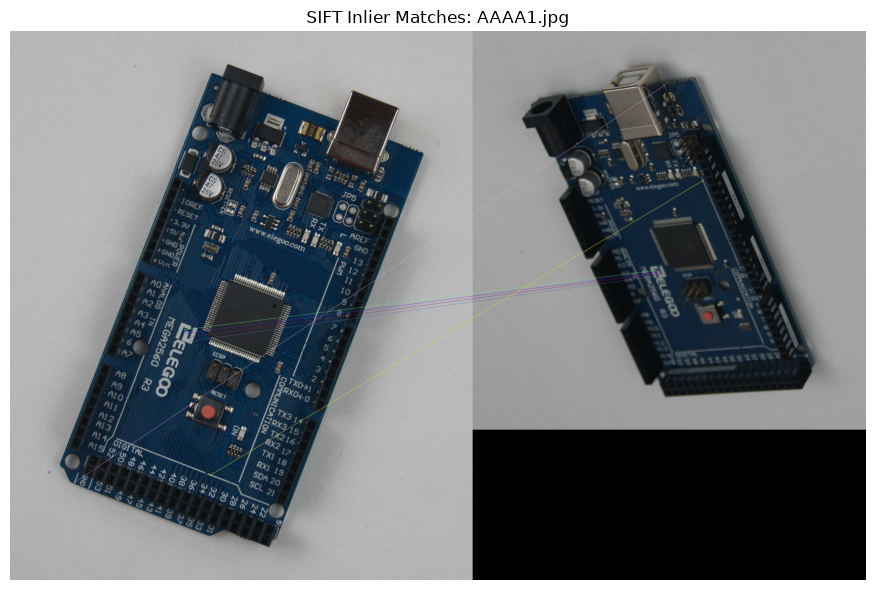


Processing: ADAD1.jpg
Good matches: 347
RANSAC inliers: 158
Inlier ratio: 45.53%


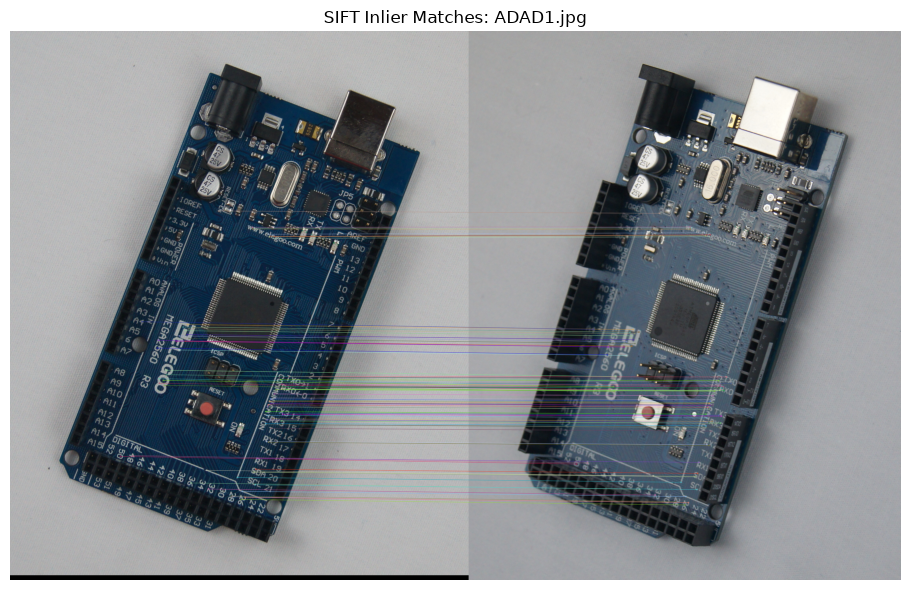


Processing: AECC2.jpg
Good matches: 2183
RANSAC inliers: 1866
Inlier ratio: 85.48%


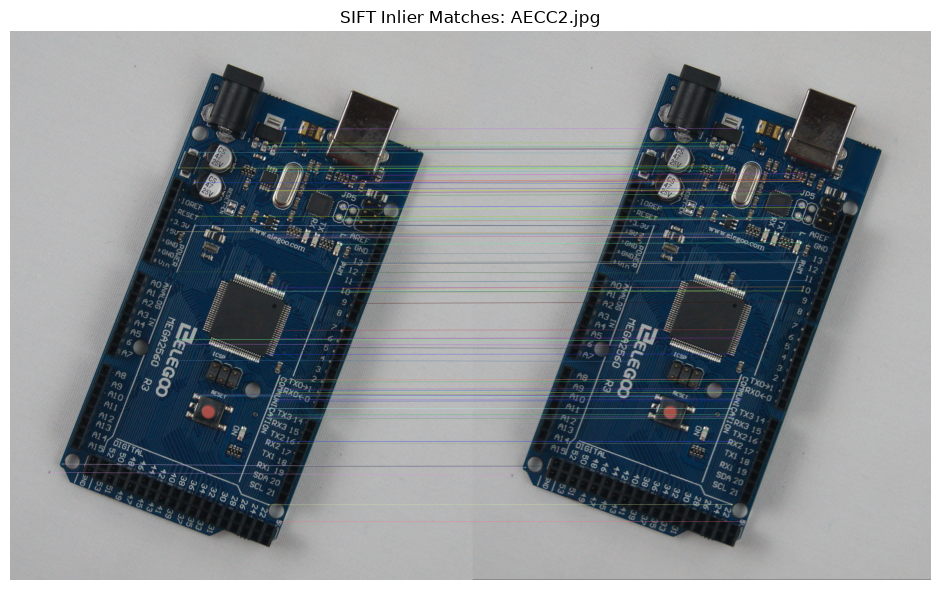


Processing: AECC3.jpg
Good matches: 2662
RANSAC inliers: 2341
Inlier ratio: 87.94%


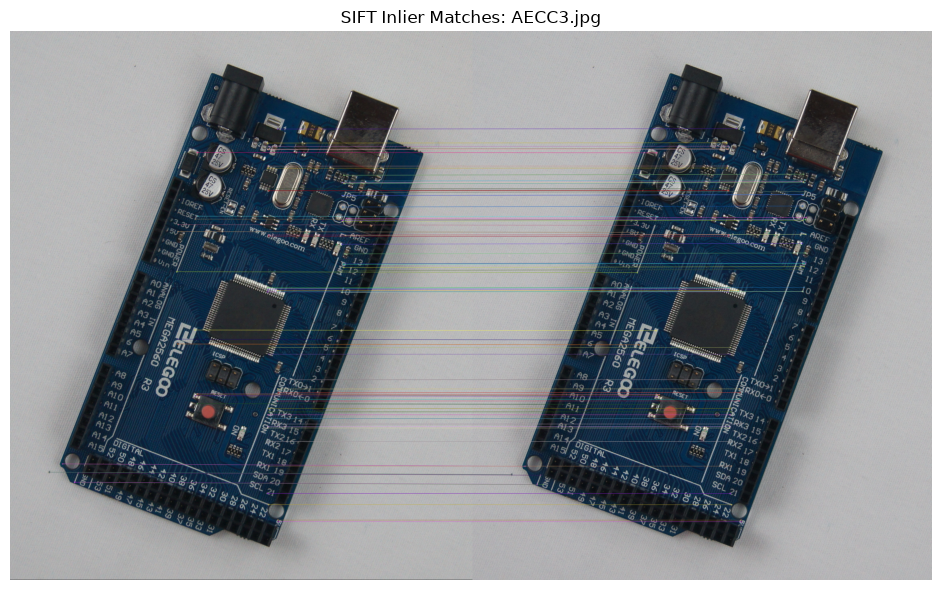


Processing: AECC4.jpg
Good matches: 1964
RANSAC inliers: 1703
Inlier ratio: 86.71%


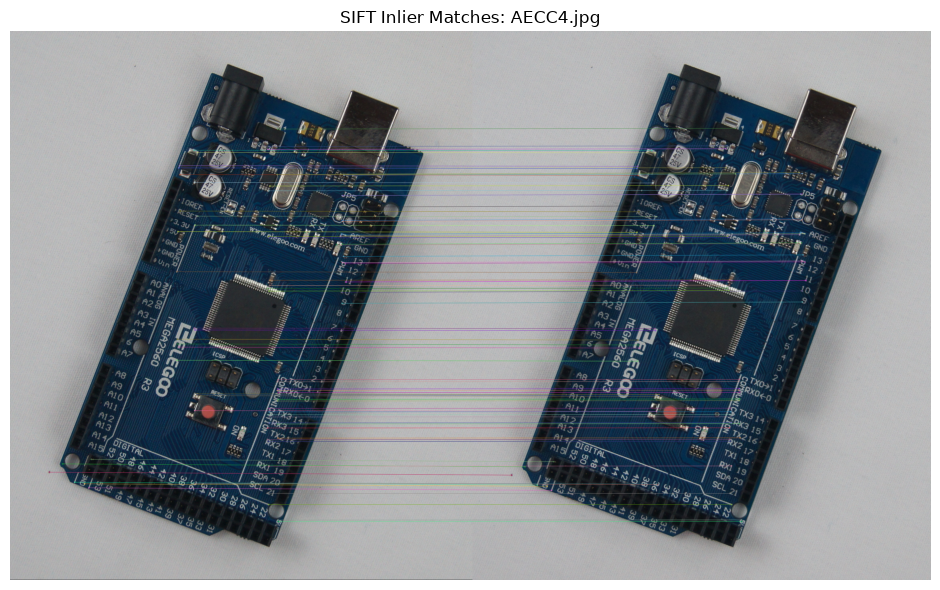


Successfully estimated homographies: 5 of 5 images.


In [35]:

# Question 4: SIFT feature matching and RANSAC homography

sift = cv2.SIFT_create(nfeatures=5000)
matcher = cv2.BFMatcher(cv2.NORM_L2)

# Extract SIFT features from the reference image
template_keypoints, template_descriptors = sift.detectAndCompute(
    template_gray, None
)

if template_descriptors is None or len(template_keypoints) < 4:
    raise RuntimeError(
        "Insufficient SIFT features in AECC1.jpg."
    )

# Store results for the next cell
pcb_results = {}

for image_path in pcb_image_paths:

    input_image = cv2.imread(str(image_path))

    if input_image is None:
        print(f"Skipping unreadable image: {image_path.name}")
        continue

    input_gray = cv2.cvtColor(
        input_image, cv2.COLOR_BGR2GRAY
    )

    input_keypoints, input_descriptors = sift.detectAndCompute(
        input_gray, None
    )

    if input_descriptors is None or len(input_keypoints) < 4:
        print(f"Insufficient features in {image_path.name}")
        continue

    # Match reference descriptors against input descriptors
    knn_matches = matcher.knnMatch(
        template_descriptors,
        input_descriptors,
        k=2
    )

    # Lowe's ratio test
    good_matches = [
        pair[0]
        for pair in knn_matches
        if len(pair) == 2
        and pair[0].distance < 0.75 * pair[1].distance
    ]

    print(f"\nProcessing: {image_path.name}")
    print("Good matches:", len(good_matches))

    if len(good_matches) < 4:
        print("Not enough matches to estimate homography.")
        continue

    # Corresponding points: input image -> reference image
    input_points = np.float32([
        input_keypoints[m.trainIdx].pt
        for m in good_matches
    ]).reshape(-1, 1, 2)

    reference_points = np.float32([
        template_keypoints[m.queryIdx].pt
        for m in good_matches
    ]).reshape(-1, 1, 2)

    H, inlier_mask = cv2.findHomography(
        input_points,
        reference_points,
        cv2.RANSAC,
        5.0
    )

    if H is None or inlier_mask is None:
        print("Homography estimation failed.")
        continue

    inlier_count = int(inlier_mask.sum())
    inlier_ratio = inlier_count / len(good_matches)

    print("RANSAC inliers:", inlier_count)
    print(f"Inlier ratio: {inlier_ratio:.2%}")

    # Visualize RANSAC inlier matches
    inlier_matches = [
        match for match, keep in
        zip(good_matches, inlier_mask.ravel())
        if keep
    ]

    match_image = cv2.drawMatches(
        template,
        template_keypoints,
        input_image,
        input_keypoints,
        inlier_matches[:100],
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    plt.figure(figsize=(14, 6))
    plt.imshow(cv2.cvtColor(match_image, cv2.COLOR_BGR2RGB))
    plt.title(f"SIFT Inlier Matches: {image_path.name}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    # Save results for the alignment cell
    pcb_results[image_path.name] = {
        "path": image_path,
        "image": input_image,
        "homography": H,
        "good_matches": good_matches,
        "inlier_count": inlier_count,
        "inlier_ratio": inlier_ratio
    }

print("\nSuccessfully estimated homographies:",
      len(pcb_results), "of", len(pcb_image_paths), "images.")


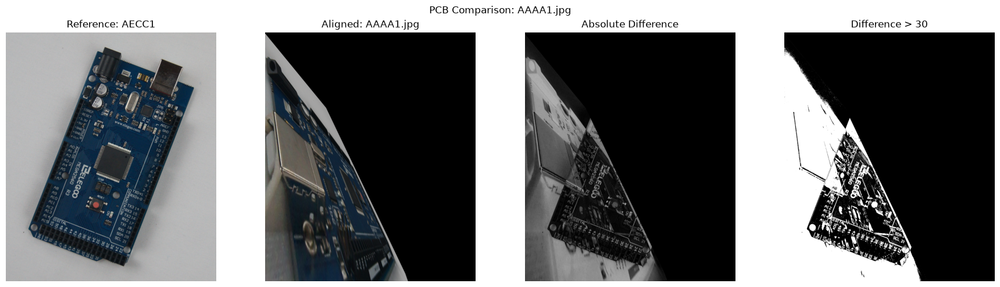


AAAA1.jpg
RANSAC inliers: 7
Valid pixels above difference threshold: 67.48%


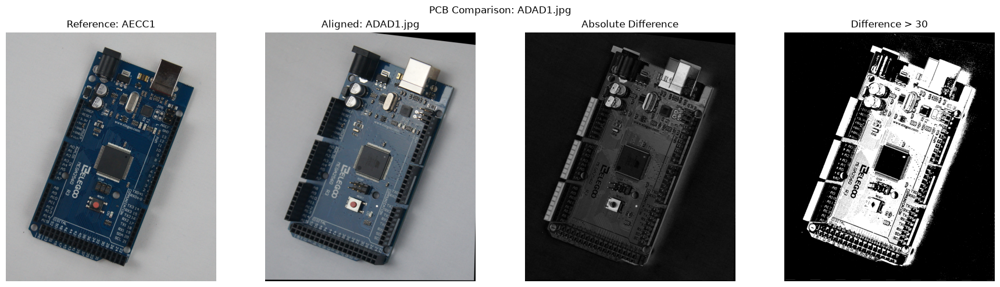


ADAD1.jpg
RANSAC inliers: 158
Valid pixels above difference threshold: 29.25%


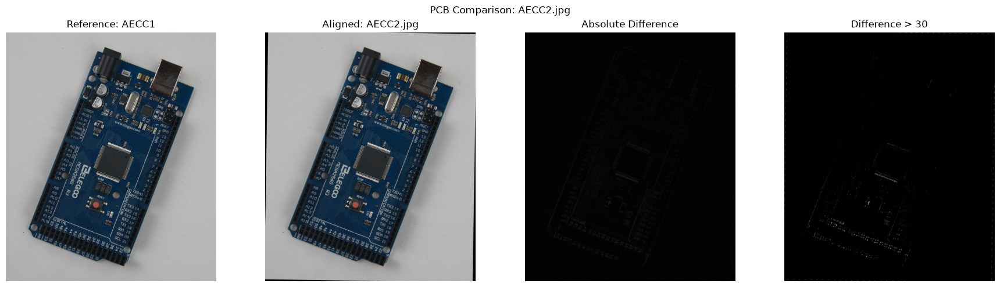


AECC2.jpg
RANSAC inliers: 1866
Valid pixels above difference threshold: 0.20%


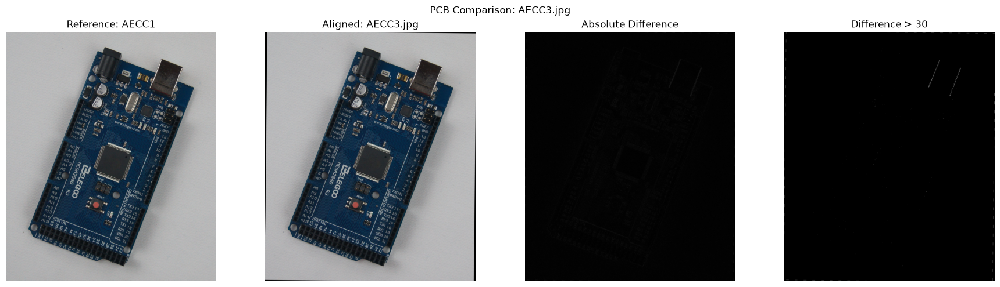


AECC3.jpg
RANSAC inliers: 2341
Valid pixels above difference threshold: 0.06%


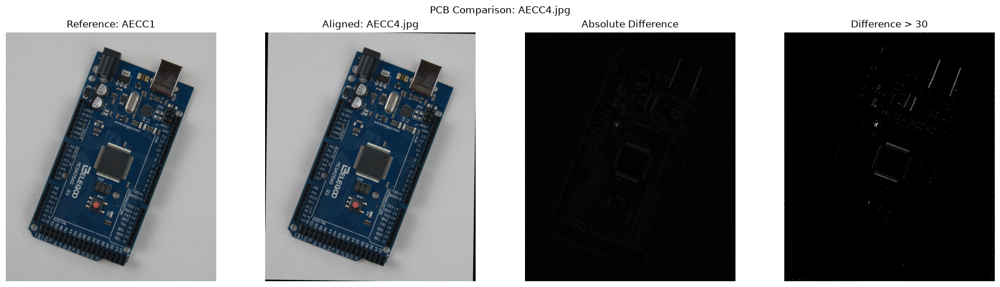


AECC4.jpg
RANSAC inliers: 1703
Valid pixels above difference threshold: 0.30%


In [36]:

# Question 4: Align PCB images and calculate absolute differences

DIFFERENCE_THRESHOLD = 30

for image_name, result in pcb_results.items():

    input_image = result["image"]
    H = result["homography"]

    # Warp the input image to the reference dimensions
    aligned_image = cv2.warpPerspective(
        input_image,
        H,
        (template.shape[1], template.shape[0])
    )

    # Warp a validity mask to identify pixels mapped from the input
    input_h, input_w = input_image.shape[:2]
    source_mask = np.full(
        (input_h, input_w), 255, dtype=np.uint8
    )

    valid_mask = cv2.warpPerspective(
        source_mask,
        H,
        (template.shape[1], template.shape[0]),
        flags=cv2.INTER_NEAREST
    )

    # Calculate pixel-wise absolute difference
    difference = cv2.absdiff(template, aligned_image)
    difference_gray = cv2.cvtColor(
        difference, cv2.COLOR_BGR2GRAY
    )

    # Threshold the difference image
    _, difference_thresholded = cv2.threshold(
        difference_gray,
        DIFFERENCE_THRESHOLD,
        255,
        cv2.THRESH_BINARY
    )

    # Exclude areas where the input image has no mapped pixels
    difference_gray[valid_mask == 0] = 0
    difference_thresholded[valid_mask == 0] = 0

    # Save results
    result["aligned_image"] = aligned_image
    result["valid_mask"] = valid_mask
    result["difference"] = difference
    result["difference_gray"] = difference_gray
    result["difference_thresholded"] = difference_thresholded

    # Display reference, aligned image, and difference results
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    axes[0].imshow(cv2.cvtColor(template, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Reference: AECC1")

    axes[1].imshow(cv2.cvtColor(aligned_image, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f"Aligned: {image_name}")

    axes[2].imshow(difference_gray, cmap="gray", vmin=0, vmax=255)
    axes[2].set_title("Absolute Difference")

    axes[3].imshow(difference_thresholded, cmap="gray")
    axes[3].set_title(f"Difference > {DIFFERENCE_THRESHOLD}")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(f"PCB Comparison: {image_name}")
    plt.tight_layout()
    plt.show()

    # Calculate the percentage of valid pixels above the threshold
    valid_pixels = valid_mask > 0

    if np.any(valid_pixels):
        changed_fraction = np.mean(
            difference_gray[valid_pixels] > DIFFERENCE_THRESHOLD
        )
        print(f"\n{image_name}")
        print("RANSAC inliers:", result["inlier_count"])
        print(
            "Valid pixels above difference threshold:",
            f"{changed_fraction:.2%}"
        )
    else:
        print(f"\n{image_name}: no valid overlap after warping.")



## Results and Discussion

### PCB Image Alignment

The PCB images were compared with AECC1.jpg, which was selected as the reference image. SIFT was used to extract keypoints and descriptors, and Lowe's ratio test was applied to identify reliable feature matches. RANSAC was used to estimate the homography while rejecting inconsistent matches.

The homography was used to warp each input PCB image into the reference image coordinate system. The feature-match visualizations and RANSAC inlier counts were examined to assess the quality of the alignment.

### Difference Image Analysis

Absolute difference images were generated by comparing the reference image with each aligned PCB image. Thresholded difference maps were also produced to highlight pixels with relatively large intensity differences. Areas without valid image overlap after warping were excluded from the difference analysis.

The following regions should be examined in the actual results:

- **USB Type-B port:** Differences around its outline, position, and surrounding connections.
- **Capacitors:** Differences in component position, shape, and appearance.
- **Reset button:** Differences around its outline and position.
- **Other regions:** Differences around component edges, circuit traces, and PCB boundaries.

### Interpretation

Large differences may result from component variations, residual misalignment, lighting, shadows, reflections, or differences between the photographed boards. A high difference value does not, by itself, establish that a component is defective.

The alignment quality and feature matches should therefore be examined before drawing conclusions about component-level differences. Images with insufficient reliable feature matches may require additional inspection.

### Conclusion

This experiment demonstrates the use of SIFT, descriptor matching, RANSAC-based homography estimation, perspective warping, and absolute difference images for PCB comparison. The resulting visualizations help identify regions that warrant further inspection, while additional evidence is needed to determine the cause of any observed differences.



## Conclusion

This assignment investigated blob detection, robust line and circle fitting, homography-based image warping, and PCB image alignment. The results demonstrate how scale-space analysis and geometric transformations can be applied to computer vision problems. The accuracy of these methods depends on parameter selection, feature quality, noise, and the quality of the input images.

## GitHub Repository

**GitHub profile:** [Insert your GitHub profile URL]

**Repository:** [Insert your assignment repository URL]
